Summarize temporal organization by ranking each transition among its available alternatives. Calculate participant summaries, compare selections and save the figure.

## Settings


In [1]:
#| code-summary: "1 — Set the parameters for this run"

# Working directory (None discovers the enclosing Git project).
project_root = None


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/lagrank"


# Analysis and uncertainty settings
confidence_level = 0.95
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "lagrank"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None  # When supplied, use this one selection instead of trial_queries.
trial_queries = [
    "jnp.equal(data['list_type'], 1)",
    "jnp.equal(data['list_type'], 2)",
    "jnp.equal(data['list_type'], 3)",
]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
selection_label = "Selected lists"
contrast_name = None  # Legend title for the selected comparisons.
complete_lists_only = True


# Figure appearance
color_cycle = None
ylim = None
yticks = None


# Repeated-item capacity
size = 3  # Maximum study positions occupied by one item.

# Artifact formats and exact local provenance
figure_formats = ["png"]
provenance_dir = None
provenance_source_paths = []
notebook_source = ""

# Explicit participant-bootstrap settings
bootstrap_method = "BCa"
n_resamples = 9999
bootstrap_seed = 0

rank_method = "lag_bins"  # Or "item_midrank" for unique study items.


In [3]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "main"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths), revision=revision, base_dir=project_root
    )


In [4]:
#| code-summary: "3 — Import packages"

import csv
import sys
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

import jaxcmr
from jaxcmr.analyses.lagrank import percentile_rank, plot_lagrank, subject_lagrank
from jaxcmr.helpers import find_project_root, resolve_project_path, generate_trial_mask, load_data, save_figure

from jaxcmr.provenance import capture_notebook


## Select the observations


In [5]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

if project_root is not None:
    root_path = resolve_project_path(project_root, Path.cwd())
elif "google.colab" in sys.modules:
    root_path = Path.cwd()
else:
    try:
        root_path = Path(find_project_root())
    except FileNotFoundError:
        root_path = Path.cwd()
print("Project directory:", root_path)

np.random.seed(plot_seed)
output_dir = resolve_project_path(output_dir, root_path)
figure_dir = resolve_project_path(figure_dir, root_path) if figure_dir is not None else output_dir
output_dir.mkdir(parents=True, exist_ok=True)

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_paths = [resolve_project_path(path, root_path) for path in input_paths]
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [6]:
#| code-summary: "4a — Capture parameters, inputs and exact local source"
provenance = capture_notebook(
    {name: globals()[name] for name in ['project_root', 'bootstrap_method', 'bootstrap_seed', 'color_cycle', 'complete_lists_only', 'confidence_level', 'contrast_name', 'data_labels', 'data_path', 'data_paths', 'figure_dir', 'figure_formats', 'figure_str', 'labels', 'max_subjects', 'n_resamples', 'notebook_source', 'output_dir', 'plot_seed', 'provenance_dir', 'provenance_source_paths', 'rank_method', 'selection_label', 'size', 'trial_queries', 'trial_query', 'ylim', 'yticks']},
    resolve_project_path(provenance_dir, root_path) if provenance_dir is not None else resolve_project_path(output_dir, root_path) / "provenance",
    [Path(jaxcmr.__file__).parent, *map(Path, provenance_source_paths)],
    notebook_source=notebook_source,
    base_dir=root_path,
)
print("Provenance:", provenance["path"])


In [7]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [8]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed: 246 lists, 123 participants
Observed / Pure emotional: 122 lists, 122 participants
Observed / Pure neutral: 123 lists, 123 participants


CMR / Mixed: 2460 lists, 123 participants
CMR / Pure emotional: 1220 lists, 122 participants
CMR / Pure neutral: 1230 lists, 123 participants
Source-only eCMR / Mixed: 2460 lists, 123 participants
Source-only eCMR / Pure emotional: 1220 lists, 122 participants
Source-only eCMR / Pure neutral: 1230 lists, 123 participants
Broader eCMR / Mixed: 2460 lists, 123 participants
Broader eCMR / Pure emotional: 1220 lists, 122 participants
Broader eCMR / Pure neutral: 1230 lists, 123 participants


In [9]:
#| code-summary: "7 — Require complete study lists for temporal analysis"

presentations = np.asarray(data["pres_itemnos"])

for dataset, masks in zip(datasets, masks_by_dataset):
    if any(
        bool(jnp.any(mask & jnp.any(dataset["pres_itemnos"] == 0, axis=1)))
        for mask in masks
    ):
        raise ValueError("This temporal procedure requires complete study lists.")


## Rank one chosen transition


In [10]:
#| code-summary: "8 — Rank one transition among its alternatives"

selected = np.logical_or.reduce([np.asarray(mask) for mask in trial_masks])
eligible = selected & ((np.asarray(data["recalls"]) > 0).sum(axis=1) >= 2)
unrepeated = np.array(
    [
        len(np.unique(items[items > 0])) == np.count_nonzero(items)
        for items in presentations
    ]
)
eligible_rows = np.flatnonzero(eligible & unrepeated)
if not len(eligible_rows):
    print(
        "No unrepeated list with two recalls to illustrate; transition-based summaries are undefined for this selection."
    )
else:
    row = int(eligible_rows[0])
    recall = np.asarray(data["recalls"])[row].astype(int)
    recall = recall[recall > 0]
    previous, chosen = recall[:2]
    available = np.flatnonzero(presentations[row] > 0) + 1
    available = available[available != previous]
    print(
        tabulate(
            {
                "Available study position": available,
                "Lag from previous recall": available - previous,
                "Chosen next": available == chosen,
            },
            headers="keys",
            floatfmt=".4g",
        )
    )
    print(f"Observed transition: {previous} to {chosen}; lag = {chosen - previous:+d}")

    distances = np.abs(available - previous)
    score = percentile_rank(jnp.asarray(abs(chosen - previous)), jnp.asarray(distances))
    print(f"Rank score for this transition: {float(score):.3f}")


  Available study position    Lag from previous recall    Chosen next
--------------------------  --------------------------  -------------
                         1                          -1              0
                         3                           1              0
                         4                           2              0
                         5                           3              0
                         6                           4              0
                         7                           5              0
                         8                           6              1
                         9                           7              0
                        10                           8              0
                        11                           9              0
                        12                          10              0
Observed transition: 2 to 8; lag = +6


Rank score for this transition: 0.400


## Summarize participants and plot


In [11]:
#| code-summary: "9 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


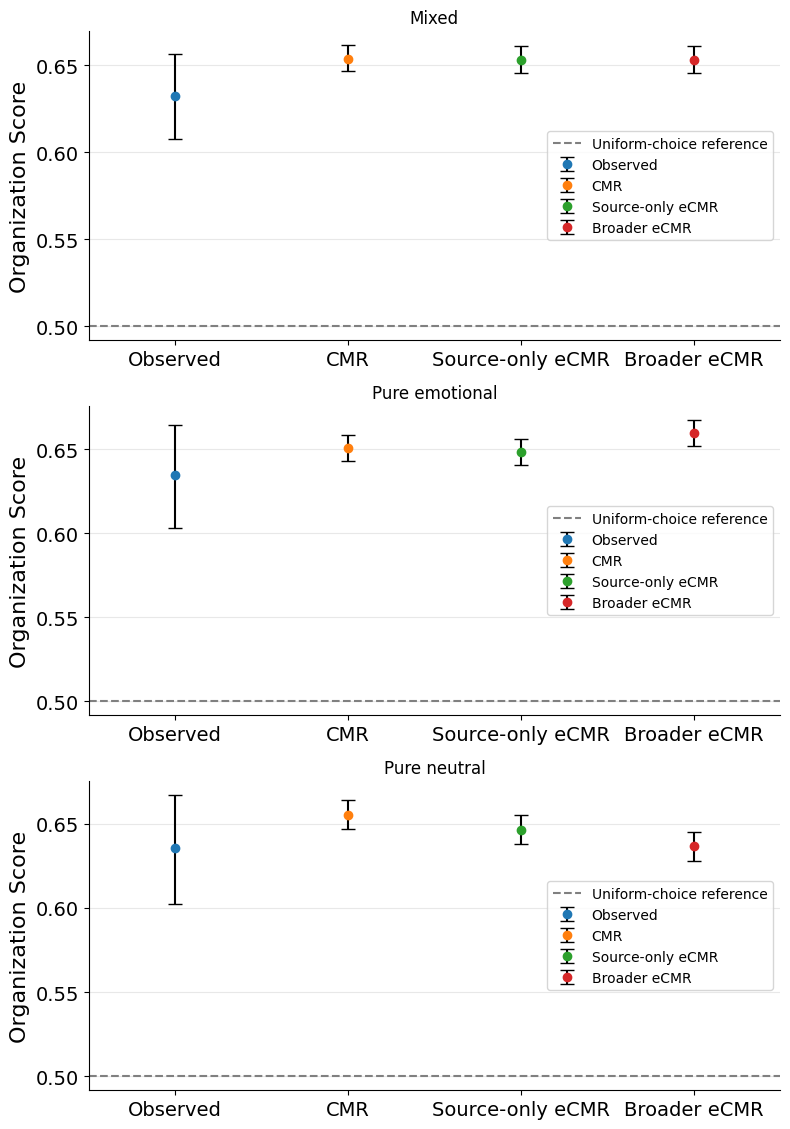

In [12]:
#| code-summary: "10 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for panel_index, (ax, panel) in enumerate(zip(axes.ravel(), panels)):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_lagrank(
        panel_data,
        panel_masks,
        size=size, rank_method=rank_method,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        bootstrap_method=bootstrap_method,
        n_resamples=n_resamples, bootstrap_seed=bootstrap_seed + panel_index * len(panel_data),
        axis=ax,
    )
    ax.axhline(0.5, color="grey", linestyle="--", label="Uniform-choice reference")
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str, formats=figure_formats)


In [13]:
#| code-summary: "11 — Calculate and summarize participant scores"

participant_rows = []
for dataset, dataset_label, condition_masks in zip(
    datasets, input_labels, masks_by_dataset
):
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_scores = np.asarray(
            subject_lagrank(dataset, condition_mask, size=size, rank_method=rank_method)
        )
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        participant_rows.extend(
            (dataset_label, condition_label, subject, score)
            for subject, score in zip(participant_ids, participant_scores)
        )
        print(
            f"{dataset_label} / {condition_label}: {np.isfinite(participant_scores).sum()} scores; mean {np.nanmean(participant_scores):.3f}"
        )


Observed / Mixed: 122 scores; mean 0.632
Observed / Pure emotional: 121 scores; mean 0.635


Observed / Pure neutral: 122 scores; mean 0.636


CMR / Mixed: 122 scores; mean 0.654
CMR / Pure emotional: 121 scores; mean 0.651


CMR / Pure neutral: 122 scores; mean 0.655
Source-only eCMR / Mixed: 122 scores; mean 0.653


Source-only eCMR / Pure emotional: 121 scores; mean 0.649
Source-only eCMR / Pure neutral: 122 scores; mean 0.646


Broader eCMR / Mixed: 122 scores; mean 0.653
Broader eCMR / Pure emotional: 121 scores; mean 0.660


Broader eCMR / Pure neutral: 122 scores; mean 0.637


In [14]:
#| code-summary: "12 — Save participant summaries as CSV"

with (output_dir / "participant_ranks.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["Dataset", "Condition", "Subject", "Rank"])
    writer.writerows(participant_rows)


In [15]:
#| code-summary: "12a — Save explicit participant-bootstrap summaries"
from jaxcmr.analyses.uncertainty import mean_interval
summary_rows = []
groups = list(dict.fromkeys((row[0], row[1]) for row in participant_rows))
for index, (dataset_label, condition_label) in enumerate(groups):
    values = [row[3] for row in participant_rows if row[:2] == (dataset_label, condition_label)]
    group_seed = bootstrap_seed + input_labels.index(dataset_label) + len(input_labels) * condition_labels.index(condition_label)
    interval = mean_interval(values, confidence_level=confidence_level, method=bootstrap_method,
                             n_resamples=n_resamples, seed=group_seed)
    summary_rows.append({"Dataset": dataset_label, "Condition": condition_label, **interval})
with (output_dir / "summary_intervals.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
